# Pattern Exploration: players, transfers, time trends and discipline
**IT3091 Machine Learning · Group 2026-DS-09**

Before modelling, this notebook looks for patterns in the data, step by step:

| Part | Question | Data | Period |
|---|---|---|---|
| 1 | Where do the players come from? Do clubs mostly use players from their own country? | `players` (citizenship) + starting XIs | 2016/17 – 2025/26 |
| 2 | How do players move between clubs and leagues, and where does the money go? | `transfers` | 2016/17 – 2025/26 |
| 3 | How do matches change over time (goals, home advantage, draws)? | Primary dataset | 2008/09 – 2025/26 |
| 4 | Player behaviour: cards and when goals are scored | `appearances`, `game_events` | 2016/17 – 2025/26 |
| 5 | What do these patterns mean for the ML model? | All of the above | |

**Important:** this notebook *describes* the data. Cards, goals and events from a match are **not** used as inputs for predicting that same match (that would be leakage). Part 5 shows which patterns could become safe, pre-match features.

Nationality, transfers, cards and goal minutes exist only in the Transfermarkt files, so Parts 1, 2 and 4 cover 2016 onward. `players.country_of_citizenship` is the player's current citizenship; it rarely changes, so it is used here for description only.

## 0. Setup

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})

IN_COLAB = "google.colab" in str(globals().get("get_ipython", lambda: "")())
DRIVE_FOLDER = "/content/drive/MyDrive/Machine Learning/Assignment"   # <- edit for Colab
if IN_COLAB:
    from google.colab import drive; drive.mount("/content/drive"); BASE = Path(DRIVE_FOLDER)
else:
    BASE = Path(os.environ.get("DE_BASE", "."))
STAGE2_DIR = BASE / "csv" / "stage_2"
PRIMARY = BASE / "European_Football_PlayerAware_Primary_9Leagues_2008_2026.csv"
FIG_DIR = BASE / "pattern_figures"; FIG_DIR.mkdir(exist_ok=True)
def save(fig, name): fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight"); plt.show()

LEAGUE_COUNTRY = {"GB1": "England", "ES1": "Spain", "IT1": "Italy", "L1": "Germany", "FR1": "France",
                  "NL1": "Netherlands", "PO1": "Portugal", "BE1": "Belgium", "SC1": "Scotland"}
LEAGUE_NAME = {"GB1": "Premier League", "ES1": "LaLiga", "IT1": "Serie A", "L1": "Bundesliga", "FR1": "Ligue 1",
               "NL1": "Eredivisie", "PO1": "Liga Portugal", "BE1": "Belgian Pro League", "SC1": "Scottish Premiership"}

primary = pd.read_csv(PRIMARY, low_memory=False, parse_dates=["date"])
tm = primary[primary.data_source == "transfermarkt_stage2"].copy()
tm_games = set(tm.game_id)
print("Primary matches:", len(primary), "| Transfermarkt matches (2016+):", len(tm))

Primary matches: 51201 | Transfermarkt matches (2016+): 28564


In [2]:
# Starting XIs of the Transfermarkt matches (large file: read in chunks)
kept = []
for ch in pd.read_csv(STAGE2_DIR / "game_lineups.csv", usecols=["game_id", "player_id", "club_id", "type", "position", "player_name"], chunksize=500_000):
    kept.append(ch[(ch["type"] == "starting_lineup") & ch.game_id.isin(tm_games)])
starters = pd.concat(kept, ignore_index=True).merge(
    tm[["game_id", "date", "season_start", "league_code", "home_team_id", "away_team_id", "home_team", "away_team"]], on="game_id")
starters = starters[(starters.club_id == starters.home_team_id) | (starters.club_id == starters.away_team_id)].copy()
starters["club"] = np.where(starters.club_id == starters.home_team_id, starters.home_team, starters.away_team)

players = pd.read_csv(STAGE2_DIR / "players.csv", usecols=["player_id", "name", "country_of_citizenship", "country_of_birth", "date_of_birth", "position"])
starters = starters.merge(players[["player_id", "country_of_citizenship", "date_of_birth", "position"]], on="player_id", how="left")
starters["league_country"] = starters.league_code.map(LEAGUE_COUNTRY)
starters["domestic"] = starters.country_of_citizenship == starters.league_country
print(f"Starter rows: {len(starters):,} | different players: {starters.player_id.nunique():,} | "
      f"citizenship known: {starters.country_of_citizenship.notna().mean():.1%}")

Starter rows: 625,232 | different players: 12,515 | citizenship known: 99.3%


---
# Part 1. Where do the players come from?
### 1.1 Share of starts by home-country players, per league and season
"Domestic" = the player's citizenship is the league's country (an English player in the Premier League, a French player in Ligue 1, ...). Measured on **starts**, so a player who starts 30 matches counts 30 times.

league_code,BE1,ES1,FR1,GB1,IT1,L1,NL1,PO1,SC1
season_start,,,,,,,,,
2016,29.9,55.2,46.4,30.9,40.9,41.5,45.3,46.1,46.5
2017,31.3,56.3,41.6,31.5,44.4,43.2,48.6,42.8,48.9
2018,28.8,58.0,42.3,28.0,39.8,42.4,50.9,36.3,47.6
2019,35.3,58.9,41.7,33.0,37.6,38.9,45.1,37.2,45.4
2020,33.4,59.6,40.7,34.0,35.1,37.1,45.3,34.5,48.7
2021,30.9,55.9,39.4,30.9,35.3,39.3,41.1,37.1,46.0
2022,33.8,55.3,36.4,30.4,33.8,39.5,44.7,35.7,38.7
2023,34.2,57.2,36.4,29.4,36.2,46.8,45.8,38.0,32.9
2024,36.3,57.0,34.0,29.0,32.6,44.4,42.3,35.0,31.5


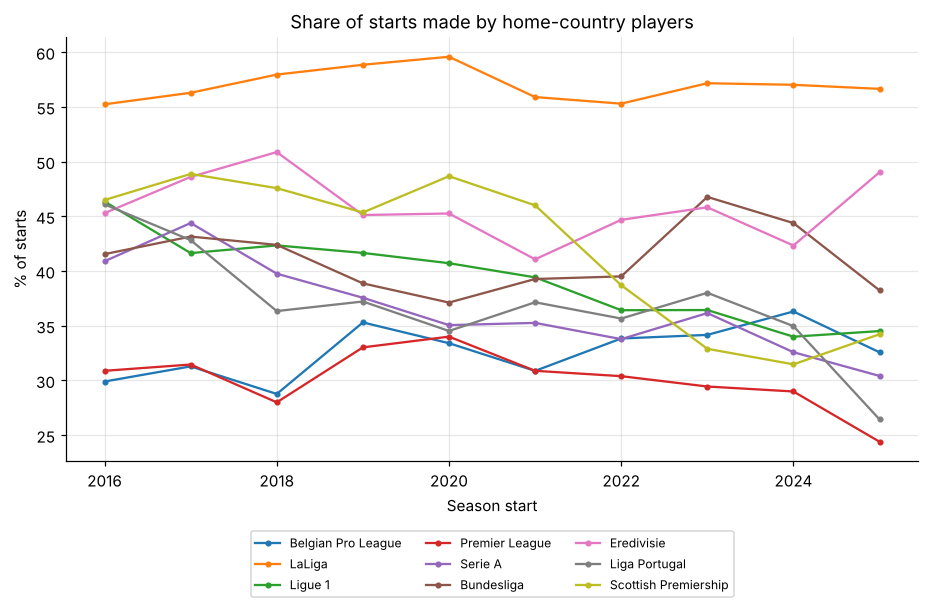

Average 2016-2026 (% of starts by home-country players):
league_code
Premier League          30.2
Belgian Pro League      32.6
Serie A                 36.6
Liga Portugal           36.9
Ligue 1                 39.6
Bundesliga              41.1
Scottish Premiership    42.1
Eredivisie              45.8
LaLiga                  57.0


In [3]:
dom = starters.groupby(["league_code", "season_start"]).domestic.mean().mul(100).unstack("league_code")
display(dom.round(1))
fig, ax = plt.subplots(figsize=(10, 5))
for lg in dom.columns:
    ax.plot(dom.index, dom[lg], marker="o", ms=3, label=LEAGUE_NAME[lg])
ax.set(title="Share of starts made by home-country players", xlabel="Season start", ylabel="% of starts")
ax.legend(ncol=3, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15))
save(fig, "1_1_domestic_share_by_league")
overall = starters.groupby("league_code").domestic.mean().mul(100).sort_values()
print("Average 2016-2026 (% of starts by home-country players):"); print(overall.round(1).rename(LEAGUE_NAME).to_string())

### 1.2 Which clubs rely most and least on home-country players?
Clubs with at least 3 seasons in the data.

In [4]:
club_dom = (starters.groupby(["league_code", "club"])
            .agg(seasons=("season_start", "nunique"), starts=("player_id", "size"), domestic_pct=("domestic", "mean")))
club_dom["domestic_pct"] *= 100
club_dom = club_dom[club_dom.seasons >= 3].reset_index()
print("Most home-country starts:"); display(club_dom.sort_values("domestic_pct", ascending=False).head(10).round(1))
print("Fewest home-country starts:"); display(club_dom.sort_values("domestic_pct").head(10).round(1))
psg = club_dom[club_dom.club.str.contains("Paris Saint", na=False)]
fr_avg = club_dom[club_dom.league_code == "FR1"].domestic_pct.mean()
print(f"Paris Saint-Germain: {psg.domestic_pct.iloc[0]:.1f}% of starts by French players (Ligue 1 club average {fr_avg:.1f}%)" if len(psg) else "PSG not found")

Most home-country starts:


,league_code,club,seasons,starts,domestic_pct
21,ES1,Athletic Bilbao,10,4136,92.0
123,L1,1. Fußballclub Heidenheim 1846,3,1122,83.5
23,ES1,CA Osasuna,8,3344,81.4
39,ES1,Real Sociedad,10,4125,77.0
27,ES1,Deportivo Alavés,9,3707,73.1
33,ES1,Levante UD,6,2464,71.9
34,ES1,RCD Espanyol Barcelona,8,3278,71.0
40,ES1,Real Valladolid CF,5,2024,70.3
192,PO1,Vitória Setúbal FC,4,1397,66.8
137,L1,SC Freiburg,10,3740,66.5


Fewest home-country starts:


,league_code,club,seasons,starts,domestic_pct
77,GB1,Brentford FC,5,2090,12.2
97,GB1,Wolverhampton Wanderers,8,3344,13.4
122,IT1,Udinese Calcio,10,4180,14.1
72,FR1,Stade Reims,7,2728,14.4
83,GB1,Fulham FC,6,2508,15.2
94,GB1,Watford FC,5,2090,20.0
14,BE1,Royal Charleroi Sporting Club,10,3421,20.0
203,SC1,Rangers FC,10,3630,20.1
84,GB1,Leeds United,4,1672,20.2
87,GB1,Manchester City,10,4180,20.7


Paris Saint-Germain: 27.1% of starts by French players (Ligue 1 club average 39.9%)


### 1.3 The most common foreign nationalities in each league

In [5]:
foreign = starters[~starters.domestic & starters.country_of_citizenship.notna()]
top_foreign = (foreign.groupby("league_code").country_of_citizenship
               .apply(lambda s: ", ".join(f"{k} {v:.0%}" for k, v in s.value_counts(normalize=True).head(5).items())))
display(top_foreign.rename(LEAGUE_NAME).to_frame("top 5 foreign nationalities (share of foreign starts)"))

,top 5 foreign nationalities (share of foreign starts)
league_code,
Belgian Pro League,"France 10%, Japan 5%, DR Congo 4%, Netherlands..."
LaLiga,"Argentina 13%, Brazil 9%, France 9%, Uruguay 7..."
Ligue 1,"Brazil 9%, Senegal 7%, Cote d'Ivoire 7%, Alger..."
Premier League,"Brazil 8%, Spain 8%, France 7%, Netherlands 6%..."
Serie A,"Argentina 9%, Brazil 8%, France 7%, Spain 5%, ..."
Bundesliga,"Austria 10%, France 9%, Switzerland 7%, Nether..."
Eredivisie,"Germany 8%, Belgium 7%, Morocco 7%, Suriname 6..."
Liga Portugal,"Brazil 41%, Spain 7%, Argentina 3%, Cape Verde..."
Scottish Premiership,"England 33%, Ireland 11%, Northern Ireland 7%,..."


### 1.4 Do clubs with more home-country players do better?
One point per club and season: share of home-country starts vs points per match. Descriptive only.

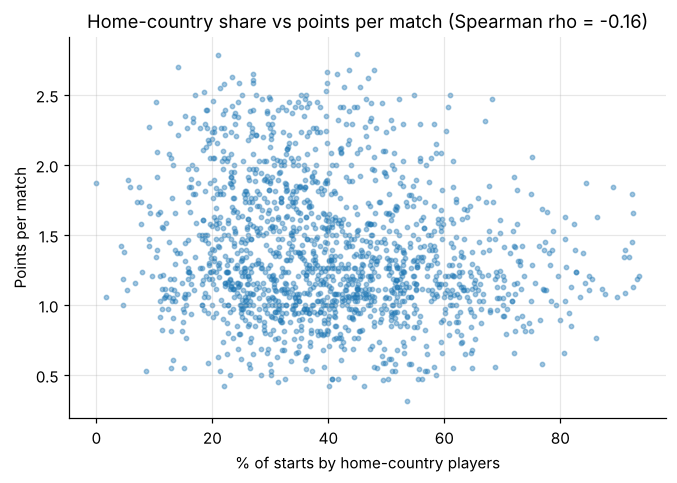

Spearman rho inside each league:
league_code
Belgian Pro League     -0.02
LaLiga                 -0.27
Ligue 1                -0.10
Premier League         -0.24
Serie A                -0.39
Bundesliga             -0.11
Eredivisie             -0.00
Liga Portugal           0.07
Scottish Premiership   -0.25


In [6]:
res = pd.concat([
    tm[["game_id", "season_start", "league_code", "home_team", "audit_home_goals", "audit_away_goals"]].set_axis(["game_id", "season_start", "league_code", "club", "gf", "ga"], axis=1),
    tm[["game_id", "season_start", "league_code", "away_team", "audit_away_goals", "audit_home_goals"]].set_axis(["game_id", "season_start", "league_code", "club", "gf", "ga"], axis=1)])
res["points"] = np.where(res.gf > res.ga, 3, np.where(res.gf == res.ga, 1, 0))
cs = res.groupby(["league_code", "season_start", "club"]).points.mean().rename("ppg").reset_index()
cs = cs.merge(starters.groupby(["league_code", "season_start", "club"]).domestic.mean().mul(100).rename("domestic_pct").reset_index())
rho = cs[["domestic_pct", "ppg"]].corr(method="spearman").iloc[0, 1]
within = cs.groupby("league_code").apply(lambda g: g[["domestic_pct", "ppg"]].corr(method="spearman").iloc[0, 1], include_groups=False)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(cs.domestic_pct, cs.ppg, s=8, alpha=0.4)
ax.set(title=f"Home-country share vs points per match (Spearman rho = {rho:.2f})", xlabel="% of starts by home-country players", ylabel="Points per match")
save(fig, "1_4_domestic_share_vs_points")
print("Spearman rho inside each league:"); print(within.rename(LEAGUE_NAME).round(2).to_string())

---
# Part 2. How do players move?
### 2.1 Transfers into, out of and between our nine leagues
Each club is assigned to the league it played in most in our data; clubs outside the nine leagues are "Other". Only transfers dated 1 July 2016 to 30 June 2026 are used (the file also contains planned future loan returns). A fee of 0 is a free transfer, loan or loan return; a missing fee is unknown.

Transfers involving our 9 leagues: 38,994 | with a known fee: 84.4% | paid (fee > 0): 21.0%


to_league,GB1,ES1,IT1,L1,FR1,NL1,PO1,BE1,SC1,Other
from_league,,,,,,,,,,
GB1,1197,272,225,192,232,102,84,104,125,1318
ES1,265,1189,160,79,112,44,134,43,5,943
IT1,232,163,2192,88,171,83,69,72,12,1429
L1,235,89,111,920,108,124,37,95,17,880
FR1,279,138,213,160,878,57,90,178,18,1031
NL1,135,42,113,127,72,739,30,87,24,836
PO1,124,124,78,33,90,23,706,33,9,1425
BE1,139,41,93,103,181,91,32,488,28,866
SC1,114,6,15,17,22,23,7,25,438,858


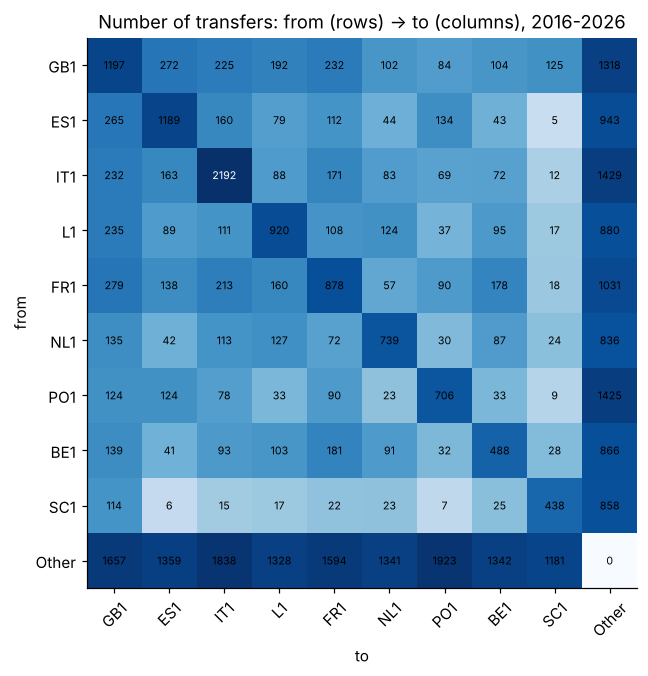

In [7]:
tr = pd.read_csv(STAGE2_DIR / "transfers.csv", parse_dates=["transfer_date"])
tr = tr[(tr.transfer_date >= "2016-07-01") & (tr.transfer_date <= "2026-06-30")].copy()
club_league = pd.concat([tm[["home_team_id", "league_code"]].set_axis(["club_id", "league_code"], axis=1),
                         tm[["away_team_id", "league_code"]].set_axis(["club_id", "league_code"], axis=1)]) \
                .groupby("club_id").league_code.agg(lambda s: s.mode().iloc[0])
tr["from_league"] = tr.from_club_id.map(club_league).fillna("Other")
tr["to_league"] = tr.to_club_id.map(club_league).fillna("Other")
tr = tr[(tr.from_league != "Other") | (tr.to_league != "Other")]
tr["fee_m"] = tr.transfer_fee / 1e6
print(f"Transfers involving our 9 leagues: {len(tr):,} | with a known fee: {tr.transfer_fee.notna().mean():.1%} | "
      f"paid (fee > 0): {(tr.transfer_fee > 0).mean():.1%}")
order = list(LEAGUE_NAME) + ["Other"]
flow = pd.crosstab(tr.from_league, tr.to_league).reindex(index=order, columns=order, fill_value=0)
flow.loc["Other", "Other"] = 0
display(flow)
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(np.log1p(flow.values), cmap="Blues")
ax.set_xticks(range(len(order)), order, rotation=45); ax.set_yticks(range(len(order)), order)
for i in range(len(order)):
    for j in range(len(order)):
        ax.text(j, i, flow.values[i, j], ha="center", va="center", fontsize=7, color="black" if flow.values[i, j] < 2000 else "white")
ax.set(title="Number of transfers: from (rows) -> to (columns), 2016-2026", xlabel="to", ylabel="from"); ax.grid(False)
save(fig, "2_1_transfer_flow_matrix")

### 2.2 Where does the money go? Spending, income and net balance per league (known fees)

,spent_eur_m,received_eur_m,net_eur_m
Premier League,23202.0,13190.0,-10012.0
Serie A,10052.0,8889.0,-1163.0
LaLiga,6626.0,6630.0,4.0
Scottish Premiership,365.0,438.0,73.0
Bundesliga,6594.0,6830.0,236.0
Belgian Pro League,1190.0,2332.0,1142.0
Ligue 1,6660.0,7903.0,1242.0
Eredivisie,1267.0,2845.0,1577.0
Liga Portugal,1926.0,3931.0,2005.0


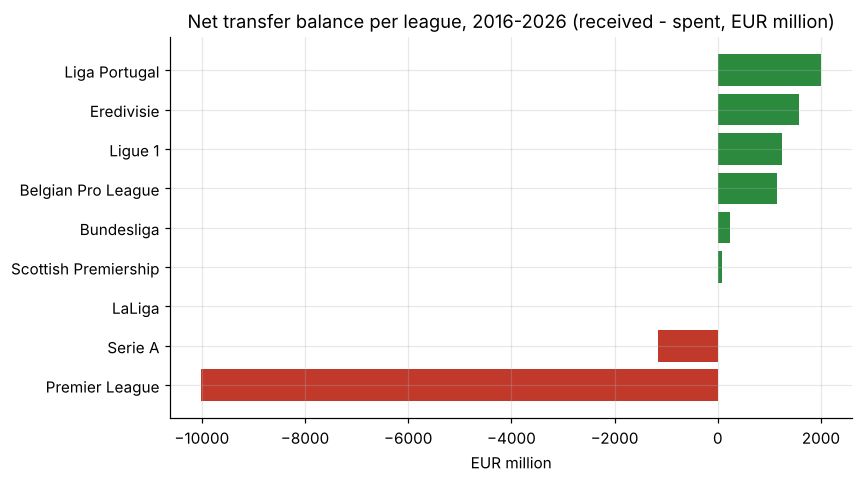

In [8]:
spend = tr[tr.to_league != "Other"].groupby("to_league").fee_m.sum()
income = tr[tr.from_league != "Other"].groupby("from_league").fee_m.sum()
money = pd.DataFrame({"spent_eur_m": spend, "received_eur_m": income}).fillna(0)
money["net_eur_m"] = money.received_eur_m - money.spent_eur_m
money = money.rename(index=LEAGUE_NAME).sort_values("net_eur_m")
display(money.round(0))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(money.index, money.net_eur_m, color=np.where(money.net_eur_m >= 0, "#2b8a3e", "#c0392b"))
ax.set(title="Net transfer balance per league, 2016-2026 (received - spent, EUR million)", xlabel="EUR million")
save(fig, "2_2_net_transfer_balance")

### 2.3 The biggest transfers, and how fees changed over time

,transfer_date,player_name,from_club_name,to_club_name,fee_m
126629,2017-08-03,Neymar,Barcelona,PSG,222.0
118188,2018-07-01,Kylian Mbappé,Monaco,PSG,180.0
126115,2017-08-25,Ousmane Dembélé,Dortmund,Barcelona,148.0
10091,2025-09-01,Alexander Isak,Newcastle,Liverpool,145.0
123886,2018-01-08,Philippe Coutinho,Liverpool,Barcelona,135.0
105263,2019-07-03,João Félix,Benfica,Atlético,127.2
48858,2023-07-01,Jude Bellingham,Dortmund,Real Madrid,127.0
15642,2025-07-01,Florian Wirtz,Leverkusen,Liverpool,125.0
55085,2023-01-31,Enzo Fernández,Benfica,Chelsea,121.0
104717,2019-07-14,Antoine Griezmann,Atlético,Barcelona,120.0


,paid_transfers,total_eur_m,median_eur_m
season,,,
2016,474,3367.91,3.50
2017,586,5032.33,3.15
2018,648,4970.15,3.20
2019,748,6930.78,4.00
2020,559,4205.81,3.00
2021,707,4544.39,2.50
2022,964,7037.54,2.98
2023,1115,8862.11,3.00
2024,1147,8801.33,3.00


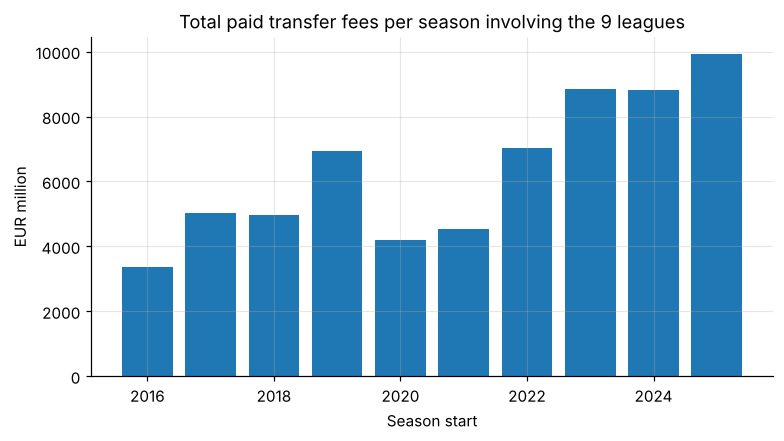

In [9]:
top = tr.sort_values("transfer_fee", ascending=False).head(10)[["transfer_date", "player_name", "from_club_name", "to_club_name", "fee_m"]].copy()
top["transfer_date"] = top.transfer_date.dt.date; top["fee_m"] = top.fee_m.round(1)
display(top)
tr["season"] = np.where(tr.transfer_date.dt.month >= 7, tr.transfer_date.dt.year, tr.transfer_date.dt.year - 1)
by_season = tr[tr.transfer_fee > 0].groupby("season").agg(paid_transfers=("fee_m", "size"), total_eur_m=("fee_m", "sum"), median_eur_m=("fee_m", "median"))
display(by_season.round(2))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_season.index, by_season.total_eur_m)
ax.set(title="Total paid transfer fees per season involving the 9 leagues", xlabel="Season start", ylabel="EUR million")
save(fig, "2_3_fees_by_season")

### 2.4 How much does a club's starting XI change between seasons?
Retention = share of last season's starters who also start for the club this season.

Median retention: 59.1%


season_start,2017,2018,2019,2020,2021,2022,2023,2024,2025
median retention %,57.1,57.1,58.3,63.0,64.0,58.0,57.1,58.6,55.6


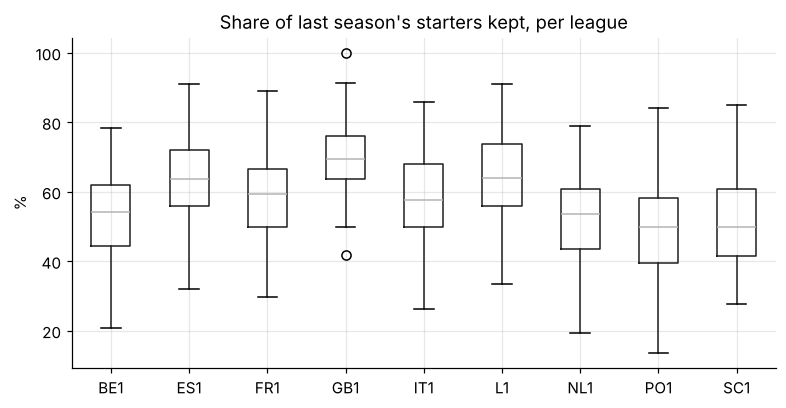

In [10]:
cs_sets = starters.groupby(["club_id", "club", "league_code", "season_start"]).player_id.agg(set).reset_index().sort_values(["club_id", "season_start"])
cs_sets["prev"] = cs_sets.groupby("club_id").player_id.shift(1); cs_sets["prev_season"] = cs_sets.groupby("club_id").season_start.shift(1)
ok = cs_sets.prev.notna() & (cs_sets.season_start - cs_sets.prev_season == 1)
cs_sets.loc[ok, "retention_pct"] = [100 * len(a & b) / len(b) for a, b in zip(cs_sets.loc[ok, "player_id"], cs_sets.loc[ok, "prev"])]
ret = cs_sets.dropna(subset=["retention_pct"])
print(f"Median retention: {ret.retention_pct.median():.1f}%")
display(ret.groupby("season_start").retention_pct.median().round(1).to_frame("median retention %").T)
fig, ax = plt.subplots(figsize=(8, 4))
ret.boxplot(column="retention_pct", by="league_code", ax=ax); plt.suptitle("")
ax.set(title="Share of last season's starters kept, per league", xlabel="", ylabel="%")
save(fig, "2_4_retention_by_league")

---
# Part 3. How do matches change over time? (2008/09 - 2025/26, all 51,201 matches)
### 3.1 Goals per match by season and league

league_code,BE1,ES1,FR1,GB1,IT1,L1,NL1,PO1,SC1
season_start,,,,,,,,,
2008,2.79,2.90,2.26,2.48,2.60,2.92,2.84,2.30,2.40
2009,2.69,2.71,2.41,2.77,2.61,2.83,2.92,2.50,2.57
2010,2.65,2.74,2.34,2.80,2.51,2.92,3.23,2.43,2.56
2011,2.88,2.76,2.52,2.81,2.58,2.86,3.26,2.64,2.64
2012,2.93,2.87,2.54,2.80,2.64,2.93,3.15,2.78,2.73
2013,2.50,2.75,2.46,2.77,2.72,3.16,3.20,2.37,2.75
2014,2.78,2.66,2.49,2.57,2.69,2.75,3.08,2.49,2.57
2015,2.89,2.74,2.53,2.70,2.58,2.83,2.98,2.72,2.85
2016,2.72,2.94,2.61,2.80,2.96,2.87,2.89,2.38,2.75


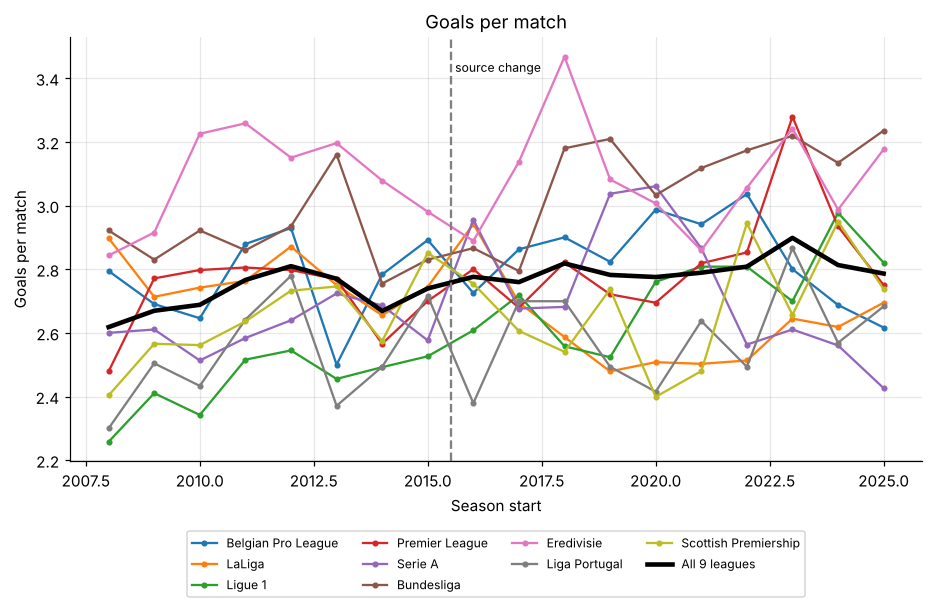

In [11]:
primary["goals"] = primary.audit_home_goals + primary.audit_away_goals
g = primary.groupby(["season_start", "league_code"]).goals.mean().unstack()
display(g.round(2))
fig, ax = plt.subplots(figsize=(10, 5))
for lg in g.columns: ax.plot(g.index, g[lg], marker="o", ms=3, label=LEAGUE_NAME[lg])
ax.plot(g.index, primary.groupby("season_start").goals.mean(), color="black", lw=3, label="All 9 leagues")
ax.axvline(2015.5, ls="--", color="grey"); ax.text(2015.6, ax.get_ylim()[1] * 0.98, "source change", fontsize=8, va="top")
ax.set(title="Goals per match", xlabel="Season start", ylabel="Goals per match")
ax.legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15))
save(fig, "3_1_goals_per_match")

### 3.2 Home advantage by league and season
Home advantage = home-win share minus away-win share. The 2020/21 season was played mostly without fans.

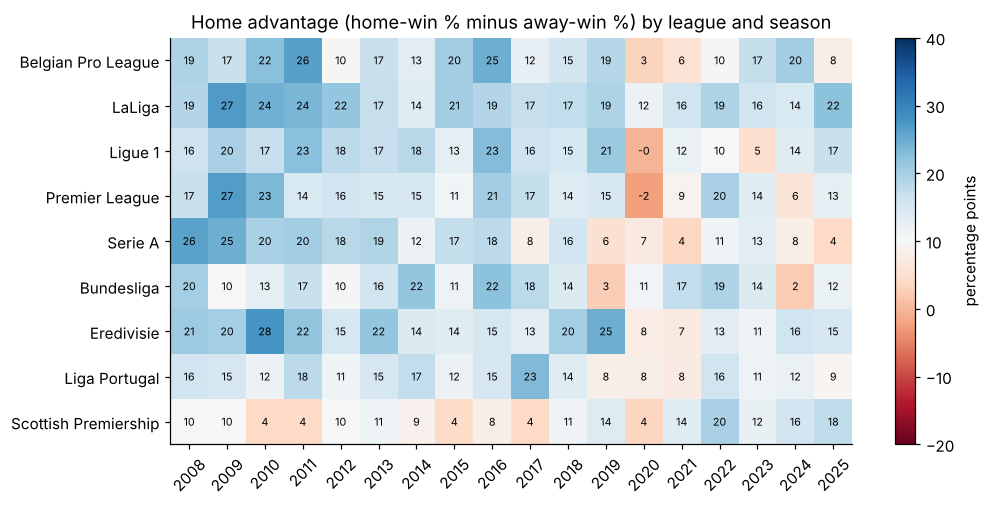

In [12]:
ha = primary.assign(h=primary.target_result.eq("H"), a=primary.target_result.eq("A")).groupby(["season_start", "league_code"])[["h", "a"]].mean()
ha = (ha.h - ha.a).mul(100).unstack()
fig, ax = plt.subplots(figsize=(10, 4.8))
im = ax.imshow(ha.T.values, aspect="auto", cmap="RdBu", vmin=-20, vmax=40)
ax.set_xticks(range(len(ha.index)), ha.index, rotation=45); ax.set_yticks(range(len(ha.columns)), [LEAGUE_NAME[c] for c in ha.columns])
for i, lg in enumerate(ha.columns):
    for j, s in enumerate(ha.index):
        v = ha.loc[s, lg]
        if pd.notna(v): ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7)
ax.set(title="Home advantage (home-win % minus away-win %) by league and season"); ax.grid(False)
fig.colorbar(im, ax=ax, label="percentage points")
save(fig, "3_2_home_advantage_heatmap")

### 3.3 Draw rate per league, and how often the stronger XI wins

In [13]:
summary = primary.groupby("league_code").agg(matches=("goals", "size"), goals_per_match=("goals", "mean"),
                                             home_win=("target_result", lambda s: (s == "H").mean()),
                                             draw=("target_result", lambda s: (s == "D").mean()),
                                             away_win=("target_result", lambda s: (s == "A").mean()))
d = primary.dropna(subset=["xi_strength_diff"]); d = d[d.target_result != "D"]
summary["stronger_XI_wins_if_not_draw"] = d.groupby("league_code").apply(
    lambda x: ((x.xi_strength_diff > 0) & (x.target_result == "H") | (x.xi_strength_diff < 0) & (x.target_result == "A")).mean(), include_groups=False)
display(summary.rename(index=LEAGUE_NAME).sort_values("draw").round(3))

,matches,goals_per_match,home_win,draw,away_win,stronger_XI_wins_if_not_draw
league_code,,,,,,
Eredivisie,5434,3.086,0.464,0.236,0.299,0.696
Scottish Premiership,3815,2.658,0.428,0.243,0.329,0.689
Premier League,6840,2.780,0.451,0.244,0.305,0.680
Bundesliga,5508,3.010,0.447,0.246,0.307,0.657
Belgian Pro League,4318,2.830,0.453,0.247,0.301,0.655
LaLiga,6840,2.685,0.470,0.249,0.282,0.674
Liga Portugal,5112,2.570,0.442,0.249,0.309,0.708
Serie A,6817,2.688,0.440,0.259,0.301,0.698
Ligue 1,6517,2.595,0.443,0.267,0.290,0.659


### 3.4 Within a season: does anything change from the first to the last month?

In [14]:
month_order = [8, 9, 10, 11, 12, 1, 2, 3, 4, 5]
m = primary[primary.date.dt.month.isin(month_order)].assign(month=lambda x: x.date.dt.month)
mm = m.groupby("month").agg(matches=("goals", "size"), goals=("goals", "mean"),
                            home_win=("target_result", lambda s: (s == "H").mean()), draw=("target_result", lambda s: (s == "D").mean())).reindex(month_order)
display(mm.round(3))

,matches,goals,home_win,draw
month,,,,
8,4207,2.723,0.426,0.257
9,5090,2.787,0.445,0.252
10,5181,2.814,0.460,0.251
11,4908,2.792,0.457,0.250
12,5632,2.743,0.448,0.252
1,5127,2.693,0.435,0.260
2,5970,2.685,0.453,0.255
3,4900,2.675,0.460,0.241
4,5498,2.806,0.455,0.241


---
# Part 4. Player behaviour: cards and goal timing (2016/17 - 2025/26)
### 4.1 Cards per match by league and season
From `appearances` (one row per player per game), only league matches of our dataset.

Games with appearance data: 28,562 of 28,564


,yellow_cards,red_cards
league_code,,
Eredivisie,3.00,0.10
Premier League,3.59,0.06
Ligue 1,3.71,0.15
Scottish Premiership,3.73,0.10
Bundesliga,3.76,0.06
Belgian Pro League,4.01,0.12
Serie A,4.37,0.09
LaLiga,4.81,0.11
Liga Portugal,5.01,0.13


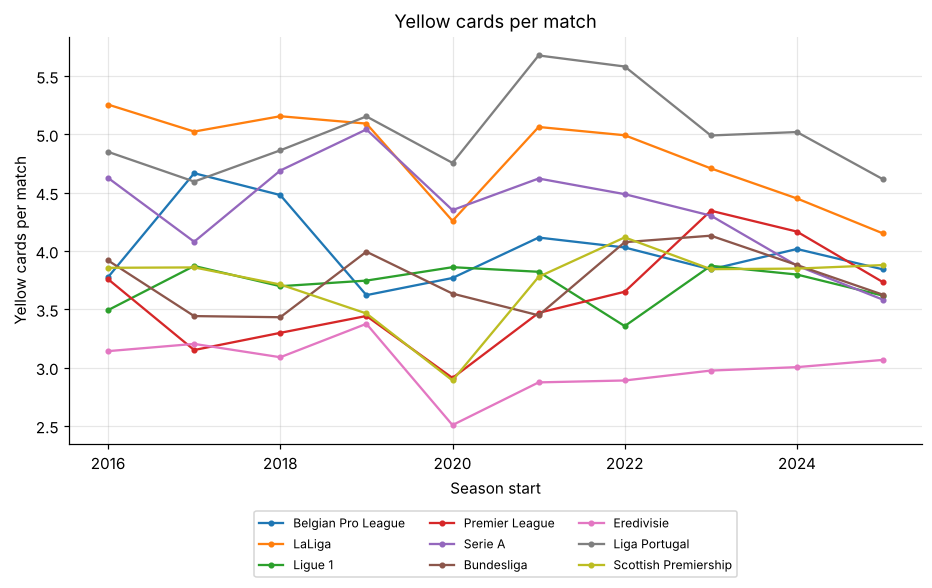

In [15]:
app = pd.read_csv(STAGE2_DIR / "appearances.csv", usecols=["game_id", "player_id", "player_club_id", "player_name", "yellow_cards", "red_cards", "goals", "assists", "minutes_played"])
app = app[app.game_id.isin(tm_games)].merge(tm[["game_id", "season_start", "league_code", "home_team_id", "target_result"]], on="game_id")
per_game = app.groupby(["game_id", "season_start", "league_code"])[["yellow_cards", "red_cards"]].sum().reset_index()
print(f"Games with appearance data: {per_game.game_id.nunique():,} of {len(tm):,}")
cards = per_game.groupby("league_code")[["yellow_cards", "red_cards"]].mean().rename(index=LEAGUE_NAME).sort_values("yellow_cards")
display(cards.round(2))
yc = per_game.groupby(["season_start", "league_code"]).yellow_cards.mean().unstack()
fig, ax = plt.subplots(figsize=(10, 4.8))
for lg in yc.columns: ax.plot(yc.index, yc[lg], marker="o", ms=3, label=LEAGUE_NAME[lg])
ax.set(title="Yellow cards per match", xlabel="Season start", ylabel="Yellow cards per match")
ax.legend(ncol=3, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15))
save(fig, "4_1_yellow_cards_by_season")

### 4.2 Cards by playing position (per 90 minutes played)

In [16]:
pos = app.merge(players[["player_id", "position"]], on="player_id", how="left")
pos = pos[pos.position.isin(["Goalkeeper", "Defender", "Midfield", "Attack"])]
per90 = pos.groupby("position").agg(minutes=("minutes_played", "sum"), yellow=("yellow_cards", "sum"), red=("red_cards", "sum"), goals=("goals", "sum"))
for c in ["yellow", "red", "goals"]: per90[f"{c}_per_90"] = per90[c] / per90.minutes * 90
display(per90[["yellow_per_90", "red_per_90", "goals_per_90"]].round(3))

,yellow_per_90,red_per_90,goals_per_90
position,,,
Attack,0.162,0.004,0.312
Defender,0.200,0.006,0.045
Goalkeeper,0.052,0.002,0.000
Midfield,0.223,0.004,0.111


### 4.3 When are goals and cards? (from `game_events`, minute of each event)

Highest minute recorded: 90 (stoppage time is recorded as 45 or 90)


type,Cards,Goals,Substitutions
period,,,
1-15,5.3,12.8,0.5
16-30,10.6,14.2,1.2
31-45 (+stoppage),18.0,17.3,1.6
46-60,14.9,16.2,17.1
61-75,18.3,16.6,37.6
76-90 (+stoppage),32.9,23.0,42.0


Note: stoppage-time events are recorded at minute 45 or 90, so the 31-45 and 76-90 bins include stoppage time and cover slightly more playing time.


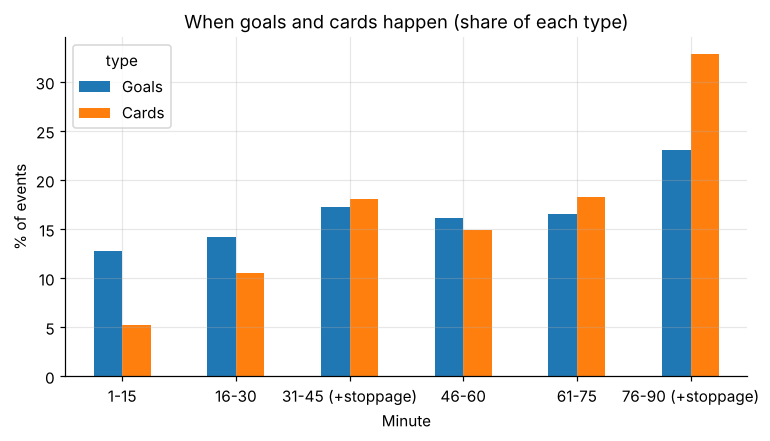

In [17]:
ev = pd.read_csv(STAGE2_DIR / "game_events.csv", usecols=["game_id", "minute", "type", "club_id"])
ev = ev[ev.game_id.isin(tm_games) & ev["type"].isin(["Goals", "Cards", "Substitutions"])]
print("Highest minute recorded:", ev.minute.max(), "(stoppage time is recorded as 45 or 90)")
bins = [0, 15, 30, 45, 60, 75, 200]; labels = ["1-15", "16-30", "31-45 (+stoppage)", "46-60", "61-75", "76-90 (+stoppage)"]
ev["period"] = pd.cut(ev.minute, bins=bins, labels=labels)
share = pd.crosstab(ev.period, ev["type"], normalize="columns").mul(100)
display(share.round(1))
print("Note: stoppage-time events are recorded at minute 45 or 90, so the 31-45 and 76-90 bins include stoppage time and cover slightly more playing time.")
fig, ax = plt.subplots(figsize=(8, 4))
share[["Goals", "Cards"]].plot.bar(ax=ax, rot=0)
ax.set(title="When goals and cards happen (share of each type)", xlabel="Minute", ylabel="% of events")
save(fig, "4_3_event_timing")

### 4.4 Red cards and the result (same match, description only)
What happens to a team that receives a red card? This is **not** a usable pre-match feature: the card happens during the match.

In [18]:
reds = app.groupby(["game_id", "player_club_id"]).red_cards.sum().reset_index()
reds = reds.merge(tm[["game_id", "home_team_id", "target_result"]], on="game_id")
reds["is_home"] = reds.player_club_id == reds.home_team_id
reds["team_result"] = np.where(reds.target_result == "D", "draw",
                       np.where((reds.target_result == "H") == reds.is_home, "win", "loss"))
reds["has_red"] = reds.red_cards > 0
display((pd.crosstab(reds.has_red, reds.team_result, normalize="index") * 100).round(1).rename(index={False: "no red card", True: "at least one red card"}))

team_result,draw,loss,win
has_red,,,
no red card,24.7,36.7,38.6
at least one red card,24.1,57.1,18.8


### 4.5 Top scorers and most carded players in the data (league matches 2016-2026)

In [19]:
tot = app.groupby(["player_id", "player_name"])[["goals", "assists", "yellow_cards", "red_cards", "minutes_played"]].sum().reset_index()
print("Top 10 scorers:"); display(tot.sort_values("goals", ascending=False).head(10))
print("Most yellow cards:"); display(tot.sort_values("yellow_cards", ascending=False).head(10))

Top 10 scorers:


,player_id,player_name,goals,assists,yellow_cards,red_cards,minutes_played
866,38253,Robert Lewandowski,274,52,31,0,26030
3240,132098,Harry Kane,262,65,37,0,27978
7245,342229,Kylian Mbappé,246,81,41,2,23439
3503,148455,Mohamed Salah,206,110,12,0,28763
574,28003,Lionel Messi,184,104,20,0,19435
8625,418560,Erling Haaland,174,42,15,0,16425
2667,105521,Ciro Immobile,171,43,44,2,22216
170,8198,Cristiano Ronaldo,151,30,25,0,16261
1562,58864,Pierre-Emerick Aubameyang,151,36,19,1,20833
2540,96341,Romelu Lukaku,146,46,29,1,22941


Most yellow cards:


,player_id,player_name,goals,assists,yellow_cards,red_cards,minutes_played
4937,221150,Dakonam Djené,1,5,97,5,27369
2244,84301,Benjamin André,17,17,96,0,26977
2875,118847,Dominik Kohr,12,12,92,2,18331
5619,255942,Nicolò Barella,28,60,87,0,26349
5631,256448,Gianluca Mancini,22,10,86,0,23362
309,16306,Casemiro,38,22,86,2,23400
2077,76746,Damián Suárez,4,17,83,2,17118
3254,133179,Marten de Roon,23,23,81,1,27939
5235,236997,Tiago Silva,31,29,78,2,15774
6293,290249,Mauro Arambarri,22,15,76,0,20842


---
# Part 5. What these patterns mean for the ML model

In [20]:
findings = pd.DataFrame([
    ("Home-country share of starts differs by league and club", "1.1-1.3", "Descriptive", "Possible pre-match feature: % of home-country starters in today's XI (known at lineup time). Not in the current model."),
    ("Home-country share vs points per match", "1.4", "Descriptive", f"Spearman rho = {rho:.2f} overall; check within leagues before using it as a feature."),
    ("Players move a lot between clubs and leagues", "2.1, 2.4", "Handled", "The model uses each match's real XI and each player's latest value, so moves are reflected automatically."),
    ("Money flows towards the richest leagues", "2.2-2.3", "Descriptive", "Explains why market values differ by league, which is why strength is ranked within league."),
    ("Goals and home advantage change over seasons (COVID dip)", "3.1-3.2", "Handled", "Chronological train / validation / test split; R script 04 tests time dependence."),
    ("Stronger XI wins most decided matches", "3.3", "Used", "This is the main signal of the model (xi_strength_diff)."),
    ("Cards differ by league, season and position", "4.1-4.2", "Descriptive", "Possible pre-match feature: a team's cards in its PREVIOUS matches (discipline, suspensions). Never the same match."),
    ("Goals and cards rise towards the end of each half", "4.3", "Simulator", "Goal-timing distribution can drive a minute-by-minute match simulation in the web app."),
    ("Red card strongly changes the result", "4.4", "Not usable", "Happens during the match: leakage if used for prediction."),
], columns=["Pattern", "Section", "Status", "Meaning for the model"])
display(findings)
findings.to_csv(FIG_DIR / "pattern_findings.csv", index=False)
print("Figures saved in", FIG_DIR)

,Pattern,Section,Status,Meaning for the model
0,Home-country share of starts differs by league...,1.1-1.3,Descriptive,Possible pre-match feature: % of home-country ...
1,Home-country share vs points per match,1.4,Descriptive,Spearman rho = -0.16 overall; check within lea...
2,Players move a lot between clubs and leagues,"2.1, 2.4",Handled,The model uses each match's real XI and each p...
3,Money flows towards the richest leagues,2.2-2.3,Descriptive,"Explains why market values differ by league, w..."
4,Goals and home advantage change over seasons (...,3.1-3.2,Handled,Chronological train / validation / test split;...
5,Stronger XI wins most decided matches,3.3,Used,This is the main signal of the model (xi_stren...
6,"Cards differ by league, season and position",4.1-4.2,Descriptive,Possible pre-match feature: a team's cards in ...
7,Goals and cards rise towards the end of each half,4.3,Simulator,Goal-timing distribution can drive a minute-by...
8,Red card strongly changes the result,4.4,Not usable,Happens during the match: leakage if used for ...


Figures saved in pattern_figures
